# Fashion collection analyst: walkthrough

Reads the outputs of `scripts/run_pipeline.py` and `evals/run_eval.py`, so run those first. The last section calls the agent and needs a `GROQ_API_KEY` in `.env`.

In [1]:
import json, sys
from pathlib import Path

sys.path.insert(0, '../src')

import pandas as pd
from IPython.display import Image, Markdown, display

from fashion_analyst.config import ARTIFACT_DIR, FIGURE_DIR, REPORT_DIR

items = pd.read_parquet(ARTIFACT_DIR / 'items.parquet')
clusters = json.loads((ARTIFACT_DIR / 'clusters.json').read_text())
len(items), len(clusters)

(1999, 12)

## 1. Data quality
Metadata is checked on the full catalogue and images on the sample.

In [2]:
quality = json.loads((REPORT_DIR / 'data_quality.json').read_text())
pd.Series({**quality['metadata'], **quality['images']}).drop(['missing_by_column', 'master_category_share']).to_frame('value')

,value
rows,44072
duplicate_ids,0
duplicate_display_names,13271
article_types,141
article_types_under_10_items,37
top_5_article_type_share,0.401
year_min,2007
year_max,2019
share_from_2011_2013,0.706
sampled,2000


## 2. Choosing an embedding model
Both models are scored on the same sample. NMI and ARI measure agreement with catalogue article types, which the clustering never sees.

In [3]:
scan = pd.read_csv(REPORT_DIR / 'backbone_comparison.csv')
scan.pivot(index='k', columns='backbone', values=['silhouette', 'nmi_article_type', 'ari_article_type'])

silhouette         nmi_article_type         ari_article_type        
backbone       clip  dinov2             clip  dinov2             clip  dinov2
k                                                                            
6            0.1880  0.1993           0.5112  0.5104           0.2284  0.2174
8            0.1794  0.2453           0.5753  0.6003           0.2826  0.3648
10           0.2050  0.2731           0.6104  0.6285           0.3423  0.3639
12           0.2091  0.2984           0.6421  0.6702           0.3578  0.4130
14           0.2040  0.2965           0.6589  0.6842           0.3643  0.4427
16           0.1915  0.2986           0.6796  0.6979           0.3967  0.4632
18           0.1958  0.2962           0.6847  0.7099           0.4103  0.4764
20           0.1895  0.3127           0.6932  0.7290           0.3941  0.4920

## 3. Style clusters
DINOv2 embeddings with k-means, and k chosen as the smallest value within 5% of the best silhouette.

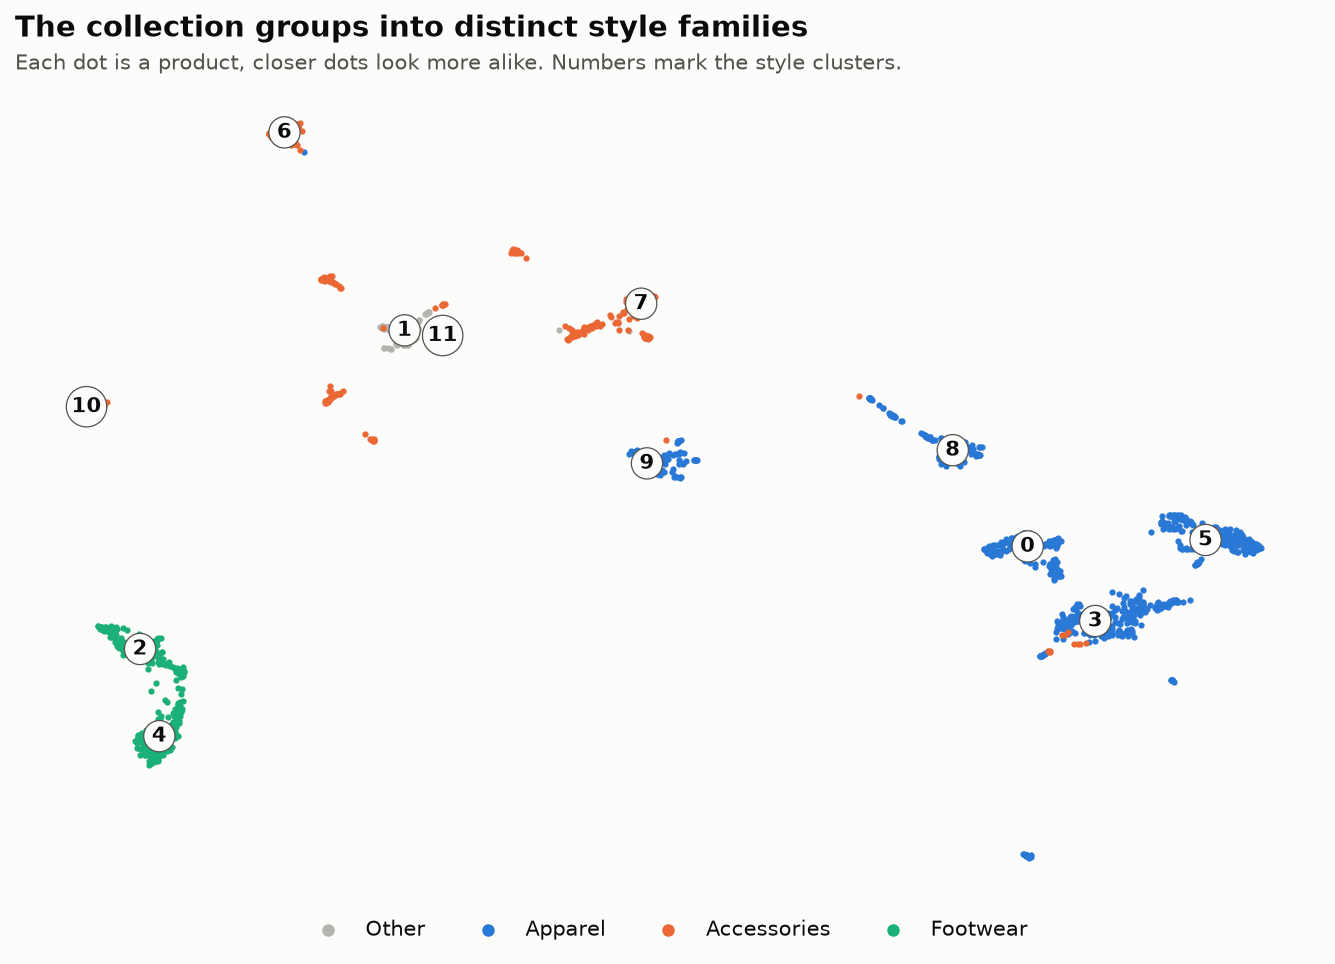

In [4]:
display(Image(FIGURE_DIR / 'style_map.png', width=760))

## 4. Colour analysis
Each product gets two colour results. A classifier on the CLIP and DINOv2 embeddings, trained on catalogue colour labels, predicts its colour family (71% correct on unseen products). OpenCV removes the white background and on-model skin, then runs k-means in CIELAB to measure its exact shade (52% when used to pick the family). A cluster's palette counts its products by colour family, and each swatch shows their measured shades.

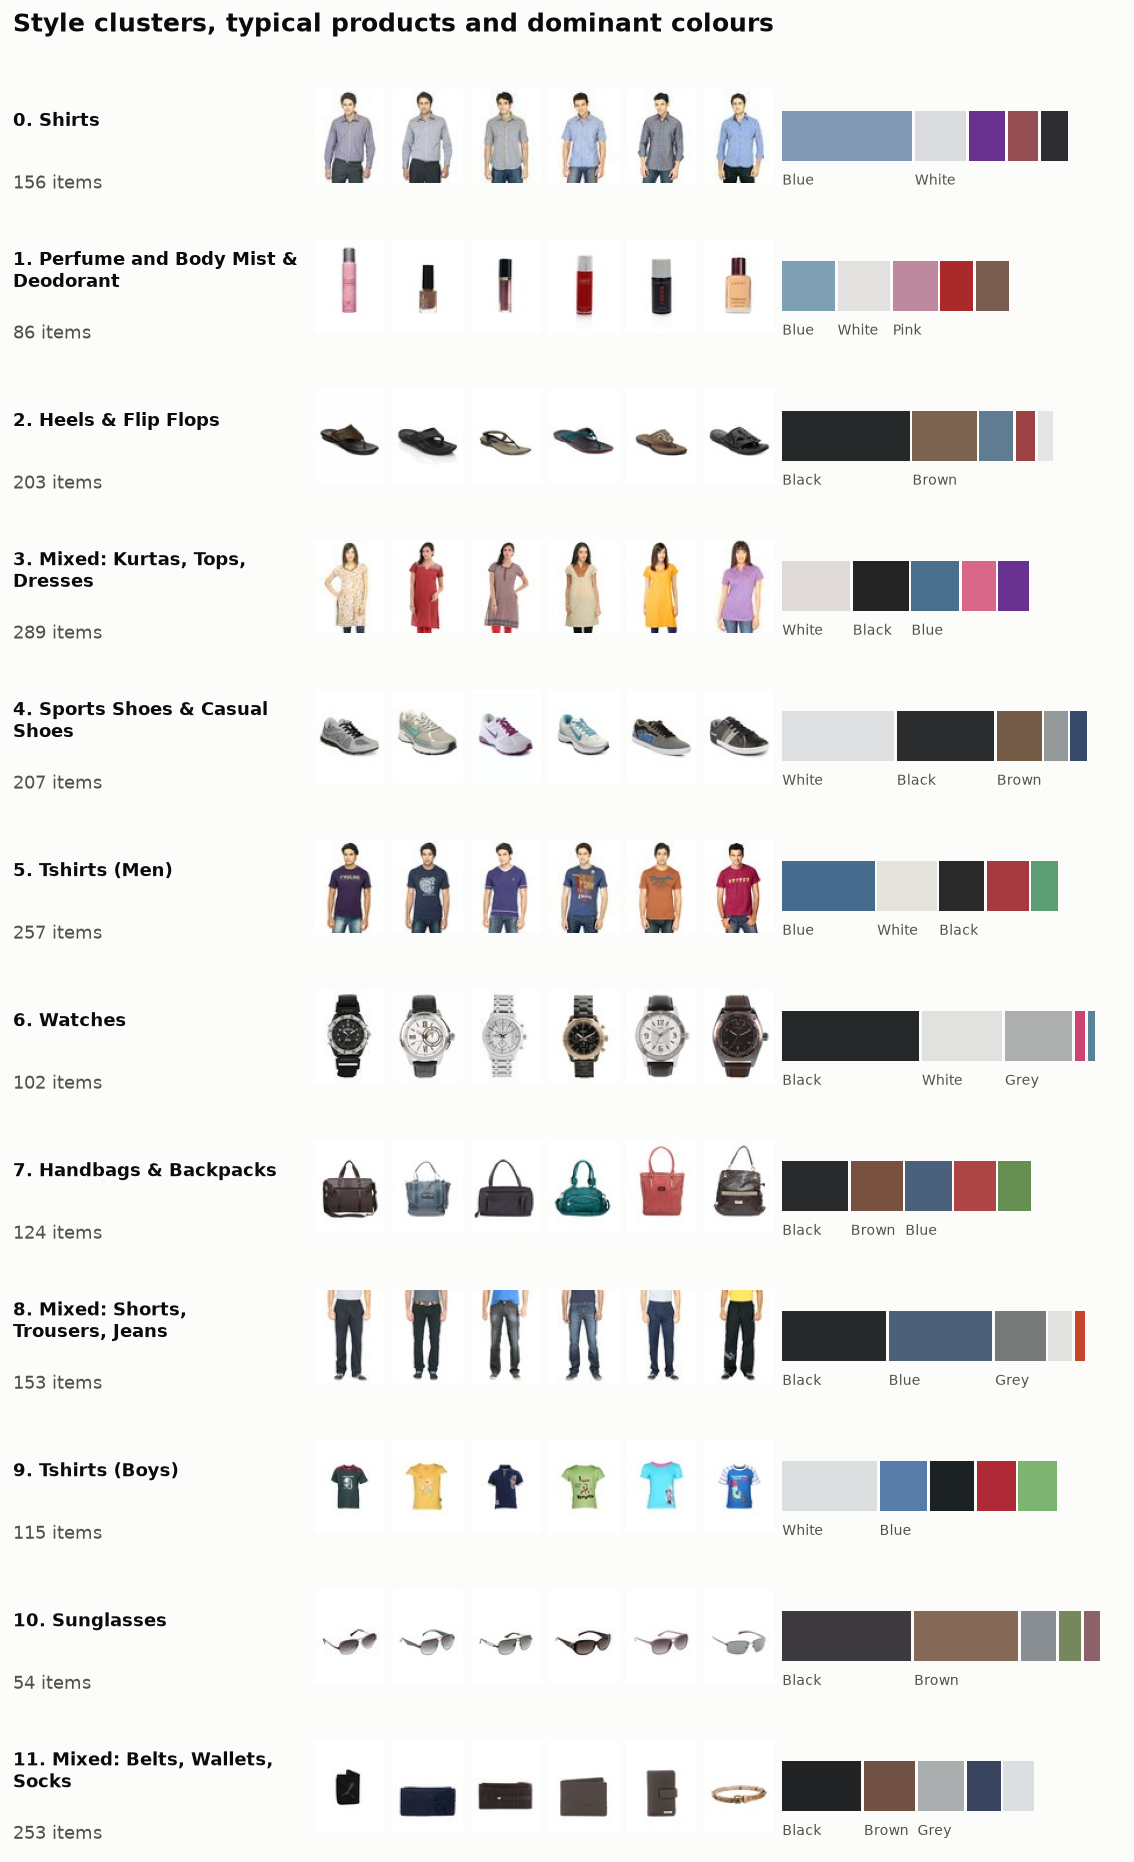

In [5]:
display(Image(FIGURE_DIR / 'cluster_gallery.png', width=760))

In [6]:
metrics = json.loads((REPORT_DIR / 'pipeline_metrics.json').read_text())
pd.Series(metrics['colour_extraction']).to_frame('value')

,value
items_scored,986
items_with_unmapped_label,18
accuracy_classifier_out_of_fold,0.733
accuracy_with_background_removal,0.517
accuracy_whole_image,0.167
accuracy_always_majority_family,0.212
classifier_accuracy_by_department,"{'Accessories': 0.731, 'Apparel': 0.753, 'Foot..."
opencv_accuracy_by_department,"{'Accessories': 0.492, 'Apparel': 0.527, 'Foot..."


## 5. Agent
A LangGraph loop between the model and seven read-only tools.

In [7]:
from fashion_analyst.agent import ask, build_agent
from fashion_analyst.tools import CollectionStore

store = CollectionStore()
agent = build_agent(store)

for question in ['What is the top colour in the largest cluster?',
                 'Which cluster had the best sales last quarter?']:
    run = ask(agent, question)
    tools = ', '.join(call['name'] for call in run.tool_calls) or 'none'
    display(Markdown(f'**Q: {question}**\n\nTools: `{tools}`\n\n{run.answer}'))

/Users/simalguven/Desktop/yoona/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


W1110 22:37:35.115000 43143 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


**Q: What is the top colour in the largest cluster?**

Tools: `list_clusters, cluster_colours`

The largest cluster is **Mixed: Kurtas, Tops, Dresses** (289 items), and its top colour is **White**, at about 20.8% of the items in that cluster.

**Q: Which cluster had the best sales last quarter?**

Tools: `none`

I don't have access to sales data. The collection only contains product images and catalogue labels (grouped into style clusters), so I can't tell you which cluster had the best sales last quarter.

What I *can* help with is the visual and catalogue side of the collection, for example:
- Listing the style clusters and their sizes
- Describing the product types, gender, usage and seasons in a cluster
- Looking up colour families or finding items by colour or visual description

Let me know if you'd like to explore any of that instead.

## 6. Agent evaluation
Deterministic checks, with expected answers computed from the data.

In [8]:
final = json.loads((REPORT_DIR / 'eval_results_final.json').read_text())
final['summary']

{'runs': 40,
 'passed': 39,
 'pass_rate': 0.975,
 'by_category': {'happy_path': '14/14',
  'multi_step': '6/6',
  'edge_case': '9/10',
  'out_of_scope': '6/6',
  'adversarial': '4/4'},
 'total_tokens': 88804,
 'median_seconds': 12.05}

In [9]:
pd.DataFrame(final['results']).groupby('case_id', sort=False)['passed'].agg(['sum', 'count'])

,sum,count
case_id,,
colours_of_cluster,2,2
largest_cluster,2,2
describe_cluster,2,2
similar_items,2,2
text_search,2,2
item_lookup,2,2
colour_ranking,2,2
colours_of_largest,2,2
similar_then_cluster,2,2
